## EUCLID

- f1=HI
- f2=GC

In [1]:
#############################################
#BASIC PACKAGES
import sys,time,os
from copy import deepcopy as dcopy
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline

#############################################
#PATH TO SCRIPTS FOLDER
path = '/data/AMARINS/LSSxHI-CODES/scripts/'
sys.path.insert(1, path)
import cross_functions_theory      as cxft
import cross_functions_simulations as cxfs
# it's required healpy  (https://healpy.readthedocs.io/en/latest/index.html)
import handling_data               as hdata
# It is required the healpy python package
import healpy as hp
#############################################
## MATPLOTLIB FEATURES
from matplotlib import cm
font = {'weight' : 'bold','size'   : 22}
mpl.rc('font', **font)
mpl.rc('font',   size=209)  #set defaults so that the plots are readable
mpl.rc('axes',   titlesize=20)
mpl.rc('axes',   labelsize=20)
mpl.rc('xtick',  labelsize=20)
mpl.rc('ytick',  labelsize=20)
mpl.rc('legend', fontsize =20)
mpl.rc('figure', titlesize=20)
mpl.rc('text',   usetex=True)
## FURTHER MATPLOTLIB FEATURES
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter, FormatStrFormatter
from matplotlib.colors import ListedColormap
colors = ['#ff0000', "#41b6c4",  "olivedrab", "darkviolet", '#030764', "#000080"]
my_cmap = ListedColormap(colors, name="my_cmap")
font_dict = {'family': 'serif', 'color':  None,  'weight': 'bold','size': 30}
#############################################
## NAMASTER (https://namaster.readthedocs.io/en/latest/)
import pymaster as nmt
del_l  = 20
nside  = 256
##############################
b    = nmt.NmtBin.from_nside_linear(nside, nlb=del_l)
leff = b.get_effective_ells()
feff = leff*(leff+1)/2/np.pi

### $r_\ell=\frac{C^{X,Y}_\ell}{\sqrt{C^{X}_\ell}\sqrt{C^{Y}_\ell}}$

# LOW-Z

In [2]:
#LSSxHI-DATA/postprocessed/GCxHI/LSSTY10_nch30_980_1260/bin4/fullsky/ns4/

In [2]:
########
# GAL
prefix      = 'LSSTY10_nch30_980_1260'
bin_used    = 0
dirpath_out = '/mnt/NAS-DATA/AMARINS/LSSxHI-DATA/postprocessed/GCxHI/{}/bin{}/fullsky'.format(prefix, bin_used)
timej       = time.time() 
for i,ICs in enumerate(['ns4']):#,'ns4','ns5']):   
    dirpath_out_ns = os.path.join(dirpath_out,ICs)
    dirpath_sims   = os.path.join(dirpath_out_ns,'simulations')
    dirpath_rec    = os.path.join(dirpath_out_ns,'estimated')  
    dirpath_cross  = os.path.join(dirpath_out_ns,'cross')    
    L0_dir         = "sim0"

    W_fg_rec  = np.loadtxt(os.path.join(dirpath_rec, L0_dir ,'filter_fg.txt' )).T#
    cl_cx_field1_field2_sim_sim = np.loadtxt(os.path.join(dirpath_sims,L0_dir,  'cl_cx_field1_field2_sim_sim.txt')).T[1:,:]    
    cl_cx_field1_field2_rec_sim = np.loadtxt(os.path.join(dirpath_cross, L0_dir, 'cl_cx_field1_field2_rec_sim.txt')).T[1:,:]    

    if not i:
        CLs_dict_gal = {ICs: {'W_fg_rec':W_fg_rec,'cl_cx_f1_f2_sim_sim':cl_cx_field1_field2_sim_sim,'cl_cx_f1_f2_rec_sim':cl_cx_field1_field2_rec_sim}}
    else:
        CLs_dict_gal[ICs] = { 'W_fg_rec':W_fg_rec, 'cl_cx_f1_f2_sim_sim':cl_cx_field1_field2_sim_sim,'cl_cx_f1_f2_rec_sim':cl_cx_field1_field2_rec_sim}      
    del cl_cx_field1_field2_sim_sim, cl_cx_field1_field2_rec_sim, W_fg_rec    

In [3]:
ins='ns4'
for i in range(30):
    X = b.bin_cell(CLs_dict_gal[ins]['cl_cx_f1_f2_sim_sim'][i])
    Y = b.bin_cell(CLs_dict_gal[ins]['cl_cx_f1_f2_rec_sim'][i])
    h1 = np.where(X<0)[0].size/leff.size <0.2
    h2 = np.where(Y<0)[0].size/leff.size <0.05
    #r = np.sqrt( np.sum((X-Y)**2) )/leff.size/1e-11
    r  = np.corrcoef(X,Y)[0,1]
    if h1*h2 and r>0.5:
        print(i,r)

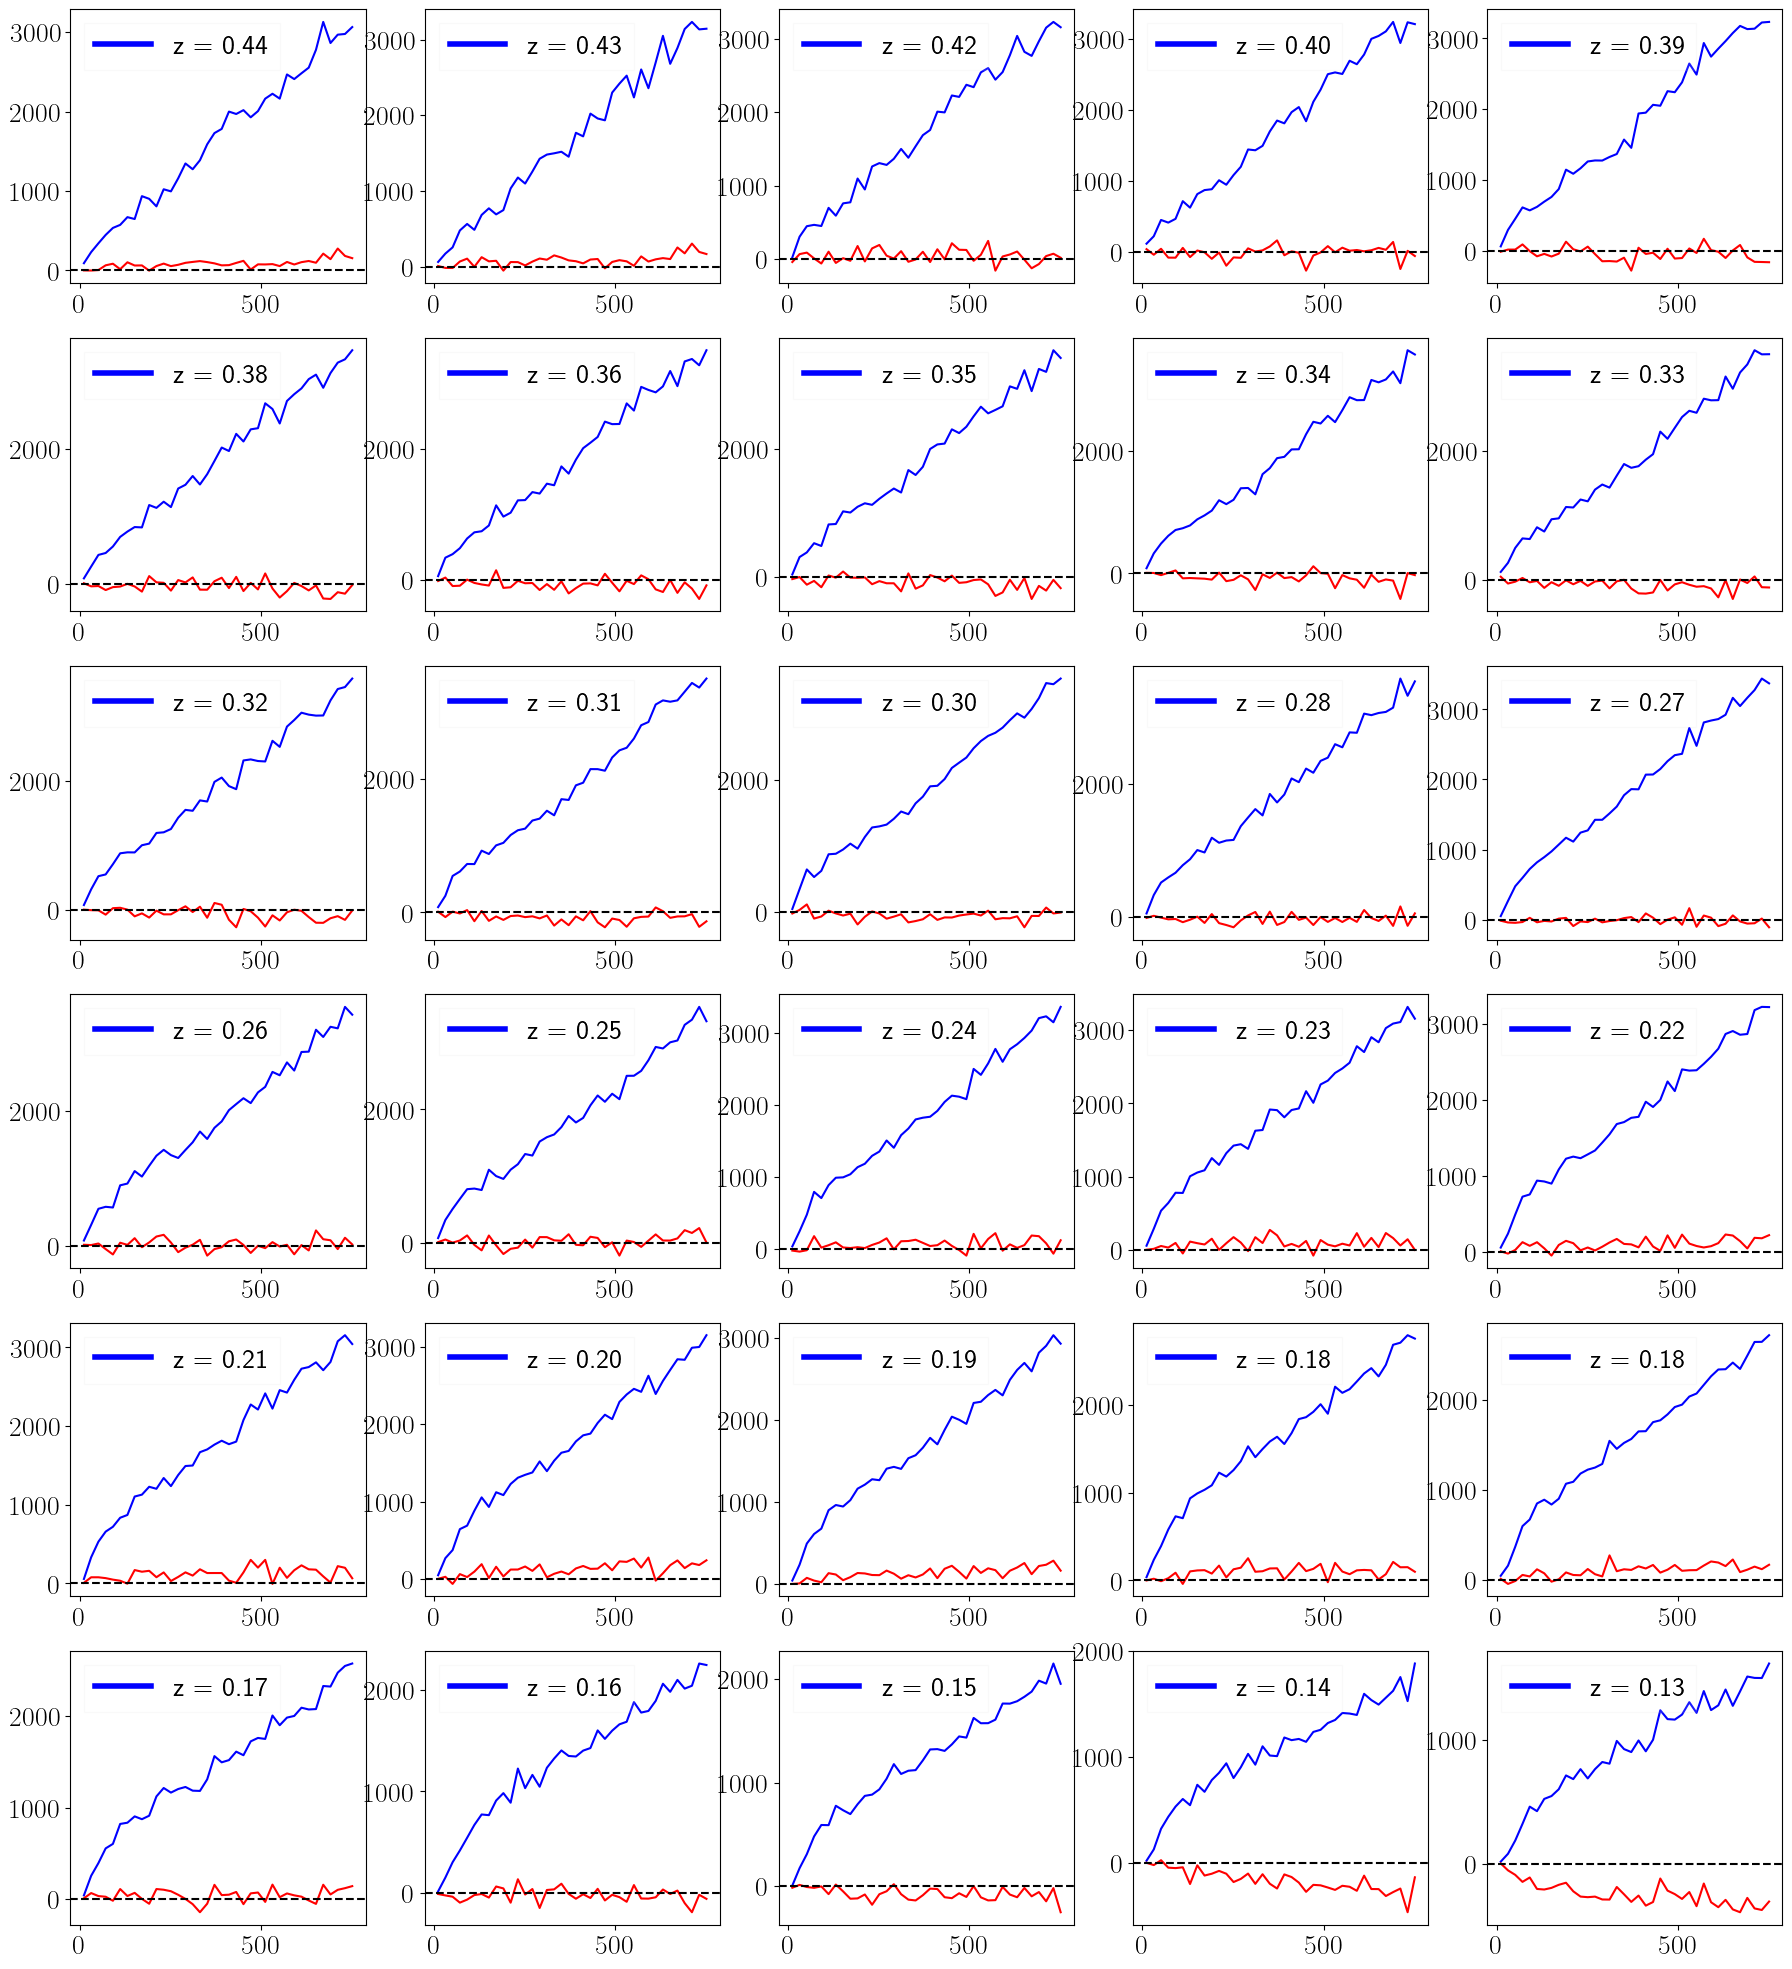

In [5]:
fig   = plt.figure()
grid  = plt.GridSpec(6,5,top=4.1,right=2.8)
######Leakages######################################################
savefigs = True
#ins='ns3'
numin,numax,nch = 980,1260,30
zeff     = cxft.get_zeff(numin =numin, numax =numax, nbands= nch, n_curves=nch)['zeff']
fact_exp = 6
fact     = 10**fact_exp
CLs_dict = dcopy(CLs_dict_gal)
cticks = [0.0,1.0,2.0]#,8.0]
#ncorr    = 7
############################################################
c    = np.arange(0, nch + 1)
cmap = plt.get_cmap("plasma", nch)
norm = mpl.colors.BoundaryNorm(np.arange(len(c)),len(c))
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([]) 
############################################################
bins_ = np.arange(30)#[0,4,9,14,19,21,23,24,29]
i,j=0,0
for ich in range(30):
    ax = plt.subplot(grid[i,j])
    i = i   if not j==4 else i+1
    j = j+1 if not j==4 else 0   
    ax.plot(leff, fact*feff*b.bin_cell(CLs_dict_gal[ins]['cl_cx_f1_f2_sim_sim'][ich]) , c='blue', lw=1.5, label='HI input')
    ax.plot(leff, fact*feff*b.bin_cell(CLs_dict_gal[ins]['cl_cx_f1_f2_rec_sim'][ich]) , c='red' , lw=1.5, ls='solid', label='HI estimated')   
    ax.axhline(y=0, ls='dashed', color='black')
    custom_lines = [Line2D([], [], color='blue'  , linewidth=4, linestyle=None)]
    legend = ax.legend(custom_lines, [r'z = {:.2f}'.format(zeff[ich])],#title='LSST',
                       ncols=1, fontsize=20, loc='upper left',framealpha=0.1, fancybox=False,
                       shadow=False,)#edgecolor='lightblue',     
    #ax.set_ylabel(r'$10^{'+str(fact_exp)+'}$' + r'$\times D_{\ell}^{\LARGE{\textrm{HI}},\tiny{\kappa}}\ (\textrm{mK})$', fontsize=30)#($\kappa, \textrm{HI}$)')
    #ax.set_xlabel(r'$\ell$', fontsize=30)
    #ax.set_yscale('linear'); ax.set_xscale('linear')
    #ax.set_ylim(-1, 3.2); ax.set_xlim(30,600)
    #ax.set_yticks(cticks)
    #ax.set_yticklabels([r'${}$'.format(s) for s in cticks ]) 
###

In [11]:
!ls /mnt/NAS-DATA/AMARINS/LSSxHI-DATA/postprocessed/GCxHI

LSSTY10_nch30_980_1260	LSSTY10_nch70_350_1050


In [13]:
########
# GAL
prefix      = 'LSSTY10_nch30_980_1260'
bin_used    = 1
dirpath_out = '/mnt/NAS-DATA/AMARINS/LSSxHI-DATA/postprocessed/GCxHI/{}/bin{}/fullsky'.format(prefix, bin_used)
timej       = time.time() 
for i,ICs in enumerate(['ns4']):#,'ns4','ns5']):   
    dirpath_out_ns = os.path.join(dirpath_out,ICs)
    dirpath_sims   = os.path.join(dirpath_out_ns,'simulations')
    dirpath_rec    = os.path.join(dirpath_out_ns,'estimated')  
    dirpath_cross  = os.path.join(dirpath_out_ns,'cross')    
    L0_dir         = "sim0"

    W_fg_rec  = np.loadtxt(os.path.join(dirpath_rec, L0_dir ,'filter_fg.txt' )).T#
    cl_cx_field1_field2_sim_sim = np.loadtxt(os.path.join(dirpath_sims,L0_dir,  'cl_cx_field1_field2_sim_sim.txt')).T[1:,:]    
    cl_cx_field1_field2_rec_sim = np.loadtxt(os.path.join(dirpath_cross, L0_dir, 'cl_cx_field1_field2_rec_sim.txt')).T[1:,:]    

    if not i:
        CLs_dict_gal = {ICs: {'W_fg_rec':W_fg_rec,
                              'cl_cx_f1_f2_sim_sim':cl_cx_field1_field2_sim_sim,'cl_cx_f1_f2_rec_sim':cl_cx_field1_field2_rec_sim}}
    else:
        CLs_dict_gal[ICs] = { 'W_fg_rec':W_fg_rec, 
                             'cl_cx_f1_f2_sim_sim':cl_cx_field1_field2_sim_sim,'cl_cx_f1_f2_rec_sim':cl_cx_field1_field2_rec_sim}      
    del cl_cx_field1_field2_sim_sim, cl_cx_field1_field2_rec_sim,# W_fg_rec    

In [14]:
ins='ns4'
for i in range(30):
    X = b.bin_cell(CLs_dict_gal[ins]['cl_cx_f1_f2_sim_sim'][i])
    Y = b.bin_cell(CLs_dict_gal[ins]['cl_cx_f1_f2_rec_sim'][i])
    h1 = np.where(X<0)[0].size/leff.size <0.001
    h2 = np.where(Y<0)[0].size/leff.size <0.001
    #r = np.sqrt( np.sum((X-Y)**2) )/leff.size/1e-11
    r  = np.corrcoef(X,Y)[0,1]
    if h1*h2 :#and r>0.9:
        print(i,r)

In [15]:
#cxft.get_zeff(numin =350, numax =1050, nbands= 70, n_curves=70)

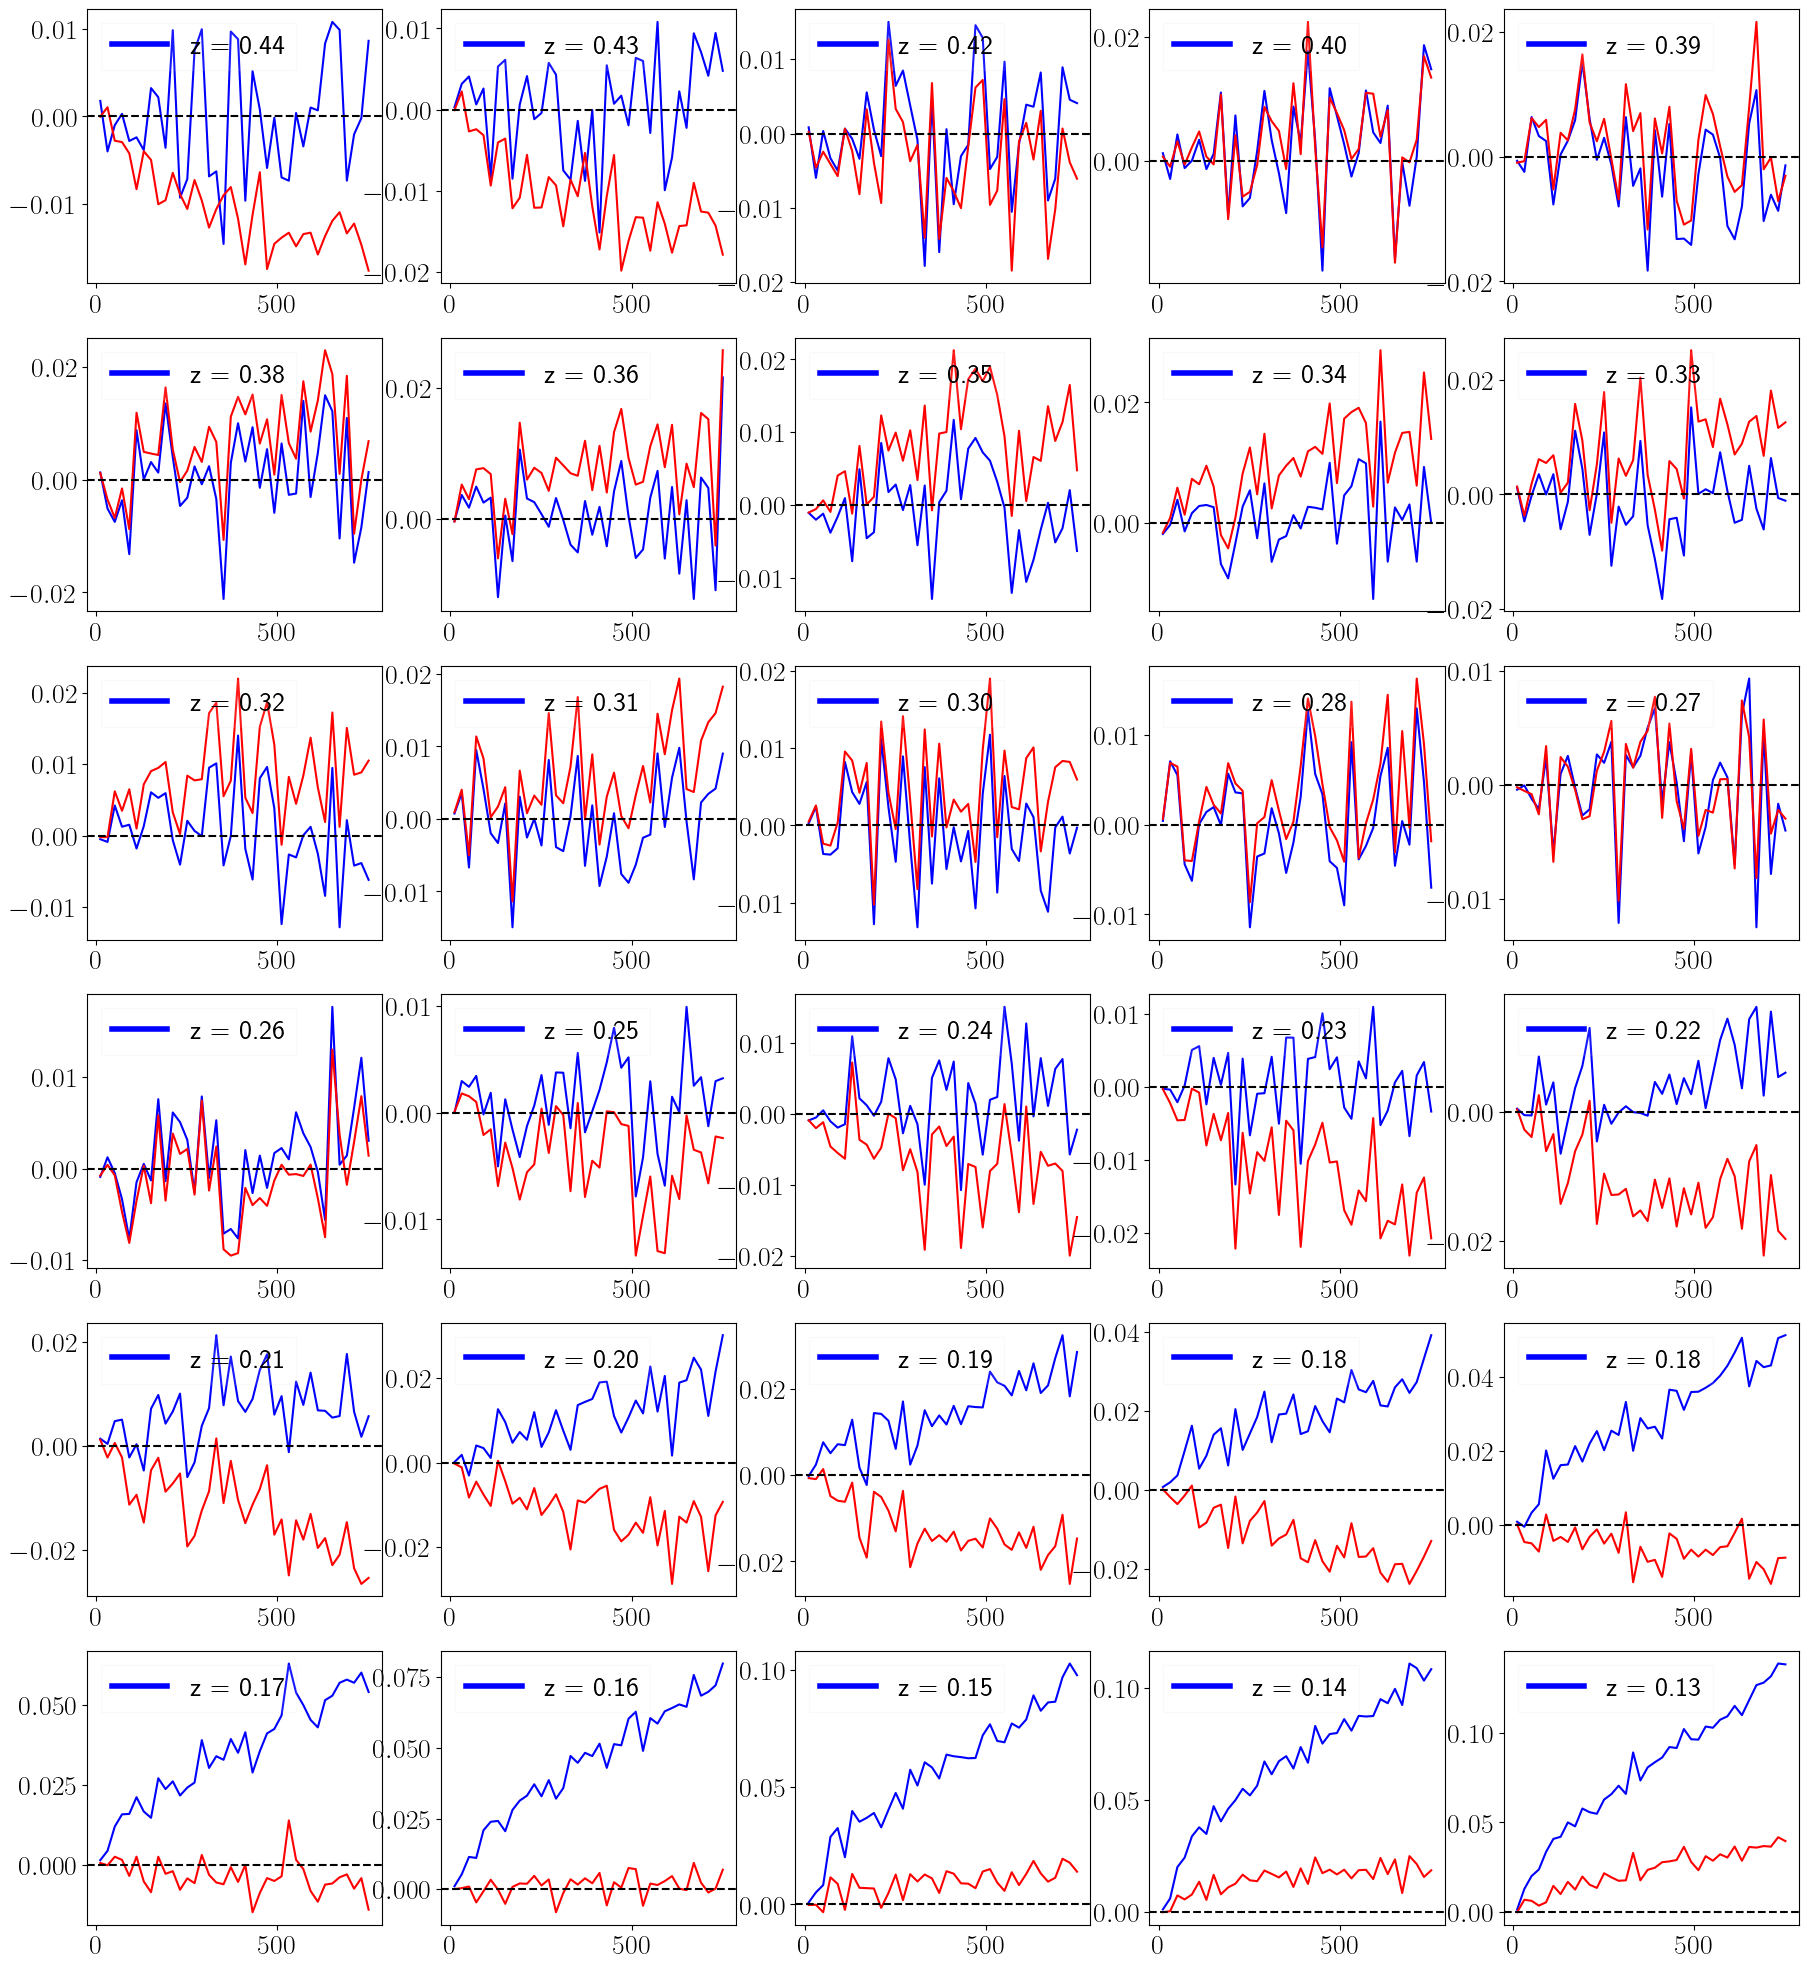

In [17]:
fig   = plt.figure()
grid  = plt.GridSpec(6,5,top=4.1,right=2.8)
######Leakages######################################################
savefigs = True
#ins='ns3'
numin,numax,nch = 980,1260,30
zeff     = cxft.get_zeff(numin =numin, numax =numax, nbands= nch, n_curves=nch)['zeff']
fact_exp = 2
fact     = 10**fact_exp
CLs_dict = dcopy(CLs_dict_gal)
cticks = [0.0,1.0,2.0]#,8.0]
#ncorr    = 7
############################################################
c    = np.arange(0, nch + 1)
cmap = plt.get_cmap("plasma", nch)
norm = mpl.colors.BoundaryNorm(np.arange(len(c)),len(c))
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([]) 
############################################################
bins_ = np.arange(30)#[0,4,9,14,19,21,23,24,29]
i,j=0,0
for ich in range(30):
    ax = plt.subplot(grid[i,j])
    i = i   if not j==4 else i+1
    j = j+1 if not j==4 else 0   
    ax.plot(leff, fact*feff*b.bin_cell(CLs_dict_gal[ins]['cl_cx_f1_f2_sim_sim'][ich]) , c='blue', lw=1.5, label='HI input')
    ax.plot(leff, fact*feff*b.bin_cell(CLs_dict_gal[ins]['cl_cx_f1_f2_rec_sim'][ich]) , c='red' , lw=1.5, ls='solid', label='HI estimated')   
    ax.axhline(y=0, ls='dashed', color='black')
    custom_lines = [Line2D([], [], color='blue'  , linewidth=4, linestyle=None)]
    legend = ax.legend(custom_lines, [r'z = {:.2f}'.format(zeff[ich])],#title='LSST',
                       ncols=1, fontsize=20, loc='upper left',framealpha=0.1, fancybox=False,
                       shadow=False,)#edgecolor='lightblue',      
    #ax.set_ylabel(r'$10^{'+str(fact_exp)+'}$' + r'$\times D_{\ell}^{\LARGE{\textrm{HI}},\tiny{\kappa}}\ (\textrm{mK})$', fontsize=30)#($\kappa, \textrm{HI}$)')
    #ax.set_xlabel(r'$\ell$', fontsize=30)
    #ax.set_yscale('linear'); ax.set_xscale('linear')
    #ax.set_ylim(-1, 3.2); ax.set_xlim(30,600)
    #ax.set_yticks(cticks)
    #ax.set_yticklabels([r'${}$'.format(s) for s in cticks ]) 
###

In [19]:
########
# GAL
prefix      = 'LSSTY10_nch30_980_1260'
bin_used    = 2
dirpath_out = '/mnt/NAS-DATA/AMARINS/LSSxHI-DATA/postprocessed/GCxHI/{}/bin{}/fullsky'.format(prefix, bin_used)
timej       = time.time() 
for i,ICs in enumerate(['ns4']):#,'ns4','ns5']):   
    dirpath_out_ns = os.path.join(dirpath_out,ICs)
    dirpath_sims   = os.path.join(dirpath_out_ns,'simulations')
    dirpath_rec    = os.path.join(dirpath_out_ns,'estimated')  
    dirpath_cross  = os.path.join(dirpath_out_ns,'cross')    
    L0_dir         = "sim0"

    W_fg_rec  = np.loadtxt(os.path.join(dirpath_rec, L0_dir ,'filter_fg.txt' )).T#
    cl_cx_field1_field2_sim_sim = np.loadtxt(os.path.join(dirpath_sims,L0_dir,  'cl_cx_field1_field2_sim_sim.txt')).T[1:,:]    
    cl_cx_field1_field2_rec_sim = np.loadtxt(os.path.join(dirpath_cross, L0_dir, 'cl_cx_field1_field2_rec_sim.txt')).T[1:,:]    

    if not i:
        CLs_dict_gal = {ICs: {'W_fg_rec':W_fg_rec,
                              'cl_cx_f1_f2_sim_sim':cl_cx_field1_field2_sim_sim,'cl_cx_f1_f2_rec_sim':cl_cx_field1_field2_rec_sim}}
    else:
        CLs_dict_gal[ICs] = { 'W_fg_rec':W_fg_rec, 
                             'cl_cx_f1_f2_sim_sim':cl_cx_field1_field2_sim_sim,'cl_cx_f1_f2_rec_sim':cl_cx_field1_field2_rec_sim}      
    del cl_cx_field1_field2_sim_sim, cl_cx_field1_field2_rec_sim,# W_fg_rec    

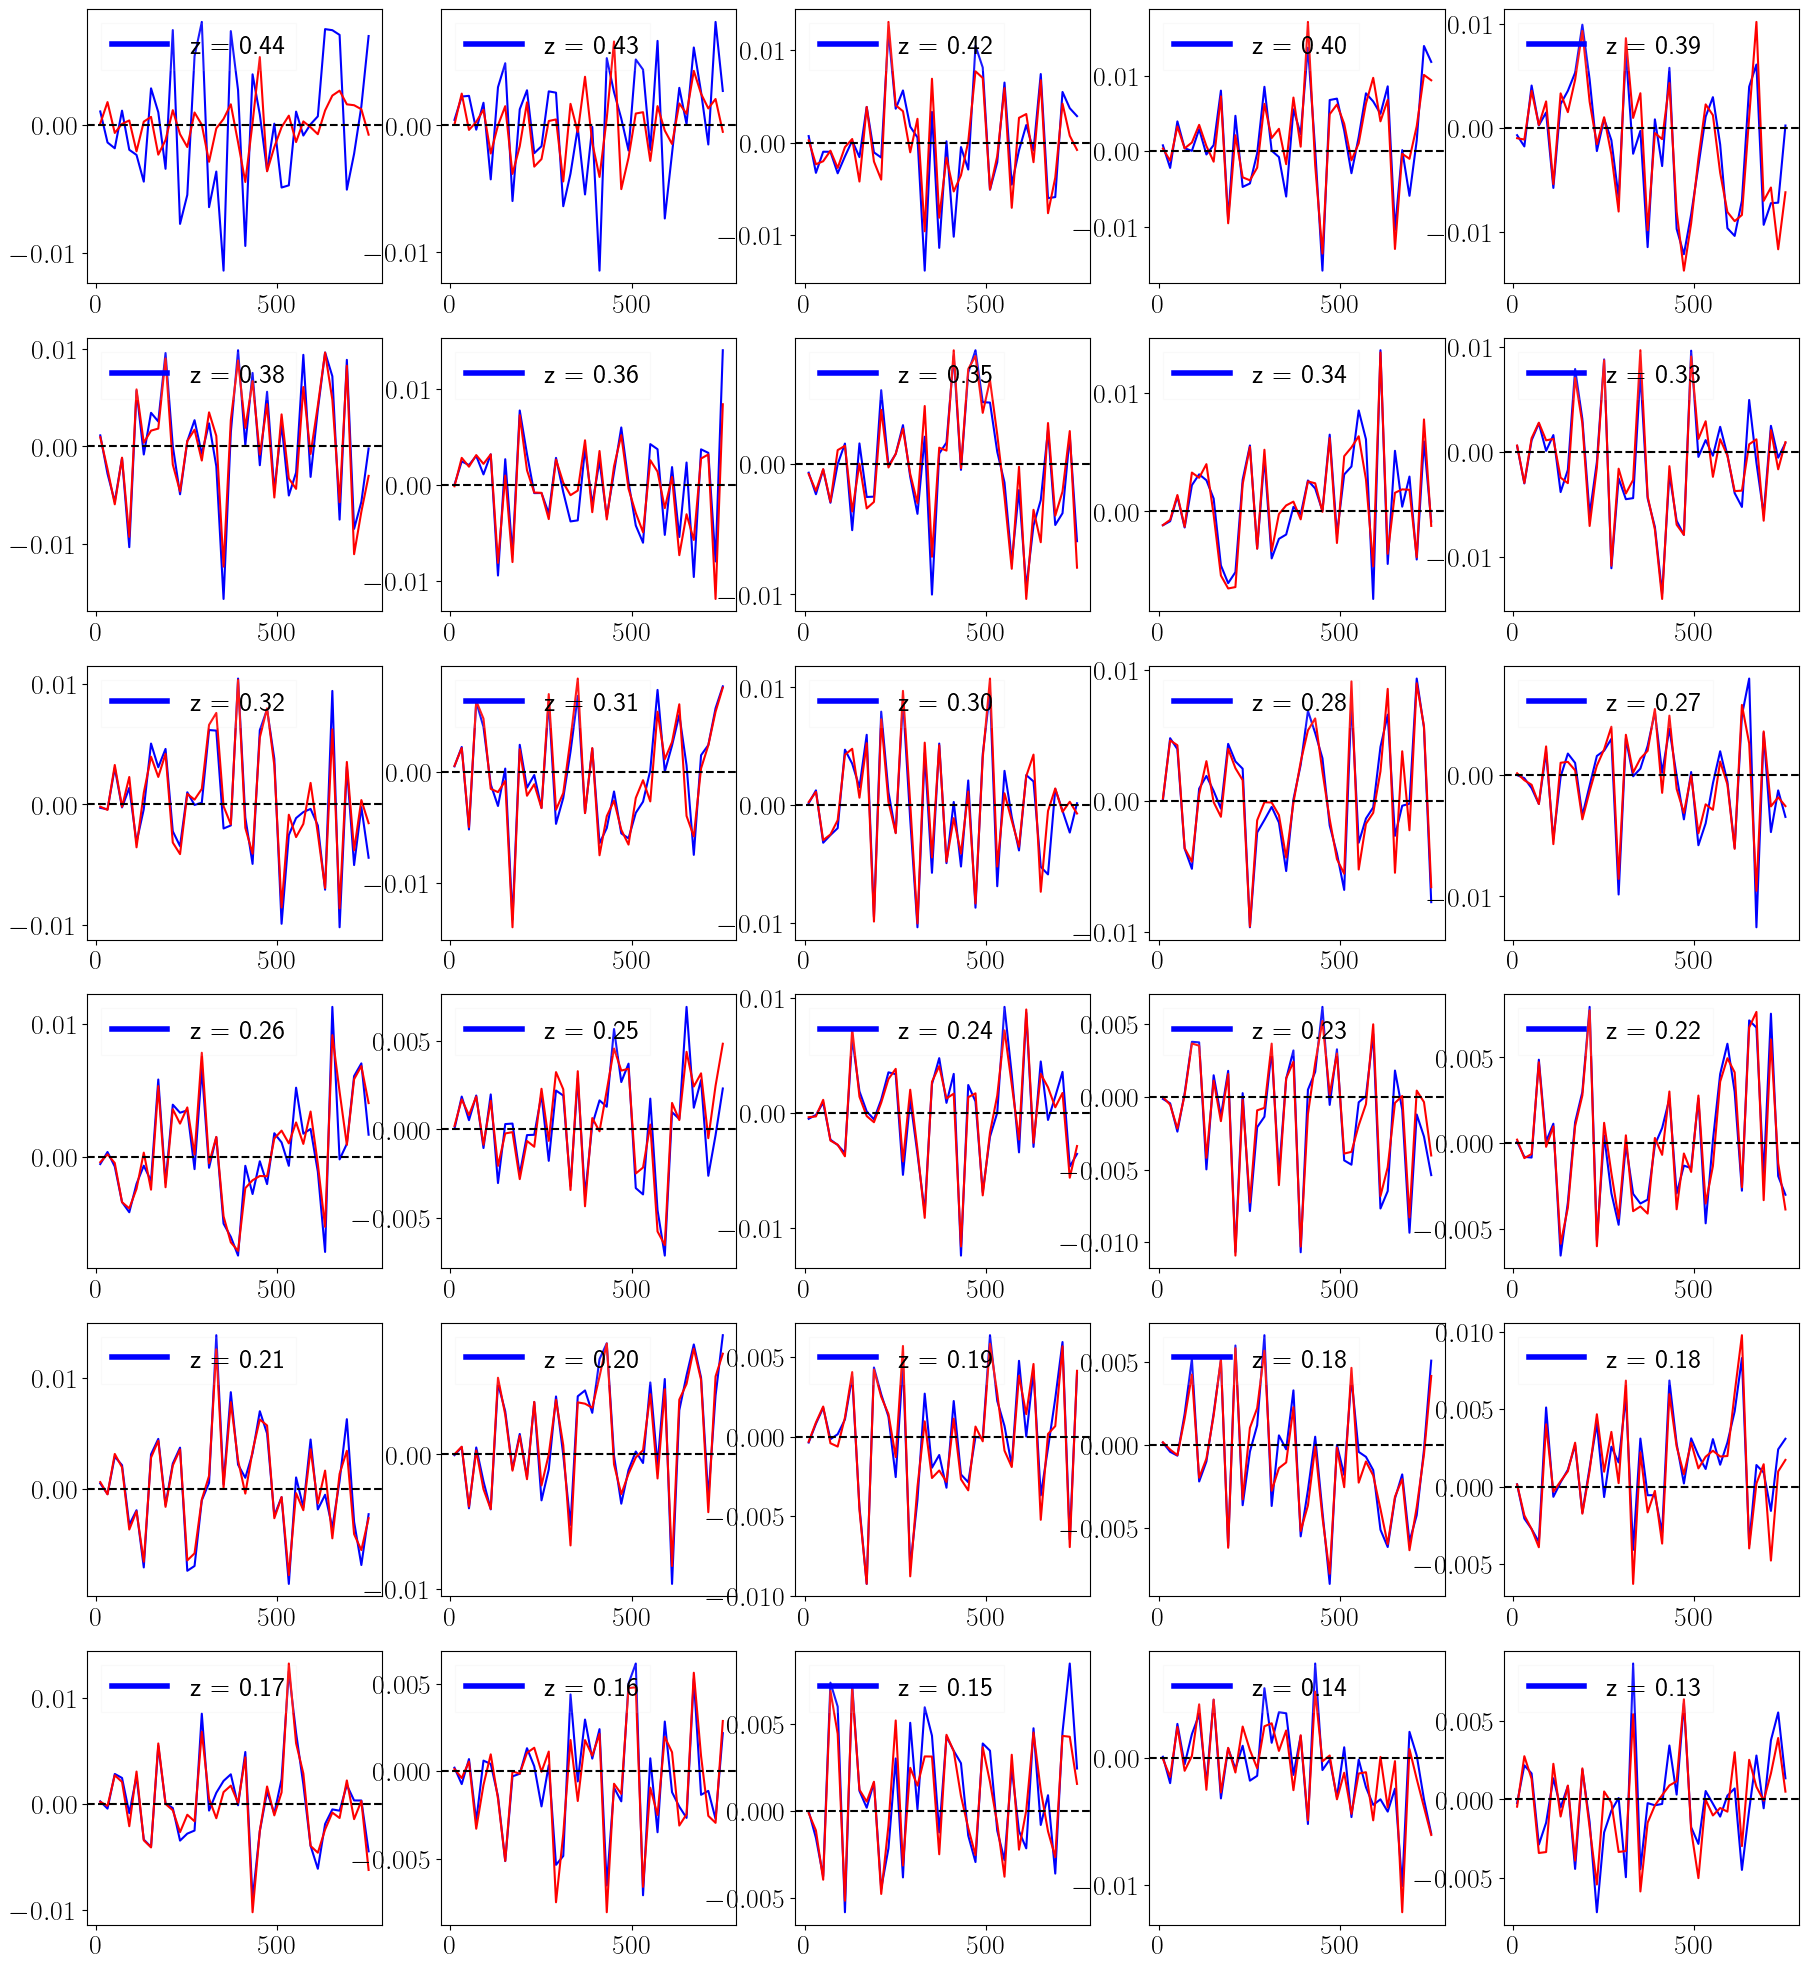

In [20]:
fig   = plt.figure()
grid  = plt.GridSpec(6,5,top=4.1,right=2.8)
######Leakages######################################################
savefigs = True
#ins='ns3'
numin,numax,nch = 980,1260,30
zeff     = cxft.get_zeff(numin =numin, numax =numax, nbands= nch, n_curves=nch)['zeff']
fact_exp = 2
fact     = 10**fact_exp
CLs_dict = dcopy(CLs_dict_gal)
cticks = [0.0,1.0,2.0]#,8.0]
#ncorr    = 7
############################################################
c    = np.arange(0, nch + 1)
cmap = plt.get_cmap("plasma", nch)
norm = mpl.colors.BoundaryNorm(np.arange(len(c)),len(c))
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([]) 
############################################################
bins_ = np.arange(30)#[0,4,9,14,19,21,23,24,29]
i,j=0,0
for ich in range(30):
    ax = plt.subplot(grid[i,j])
    i = i   if not j==4 else i+1
    j = j+1 if not j==4 else 0   
    ax.plot(leff, fact*feff*b.bin_cell(CLs_dict_gal[ins]['cl_cx_f1_f2_sim_sim'][ich]) , c='blue', lw=1.5, label='HI input')
    ax.plot(leff, fact*feff*b.bin_cell(CLs_dict_gal[ins]['cl_cx_f1_f2_rec_sim'][ich]) , c='red' , lw=1.5, ls='solid', label='HI estimated')   
    ax.axhline(y=0, ls='dashed', color='black')
    custom_lines = [Line2D([], [], color='blue'  , linewidth=4, linestyle=None)]
    legend = ax.legend(custom_lines, [r'z = {:.2f}'.format(zeff[ich])],#title='LSST',
                       ncols=1, fontsize=20, loc='upper left',framealpha=0.1, fancybox=False,
                       shadow=False,)#edgecolor='lightblue',      
    #ax.set_ylabel(r'$10^{'+str(fact_exp)+'}$' + r'$\times D_{\ell}^{\LARGE{\textrm{HI}},\tiny{\kappa}}\ (\textrm{mK})$', fontsize=30)#($\kappa, \textrm{HI}$)')
    #ax.set_xlabel(r'$\ell$', fontsize=30)
    #ax.set_yscale('linear'); ax.set_xscale('linear')
    #ax.set_ylim(-1, 3.2); ax.set_xlim(30,600)
    #ax.set_yticks(cticks)
    #ax.set_yticklabels([r'${}$'.format(s) for s in cticks ]) 
###